In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("../data/telco_clean.csv")
print(df.shape)
df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [2]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate train:", y_train.mean().round(3))
print("Churn rate test: ", y_test.mean().round(3))

Train: (5634, 19)  Test: (1409, 19)
Churn rate train: 0.265
Churn rate test:  0.265


In [3]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [4]:
baseline = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

baseline.fit(X_train, y_train)

print("Train accuracy:", round(baseline.score(X_train, y_train), 3))
print("Test accuracy: ", round(baseline.score(X_test, y_test), 3))

Train accuracy: 0.753
Test accuracy:  0.738


In [5]:
X_tr = preprocess.fit_transform(X_train)
print("Shape after encoding:", X_tr.shape)

Shape after encoding: (5634, 46)


In [6]:
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    precision_recall_curve, PrecisionRecallDisplay
)
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
import matplotlib.pyplot as plt

              precision    recall  f1-score   support

        Stay       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409

ROC-AUC: 0.842
PR-AUC:  0.633


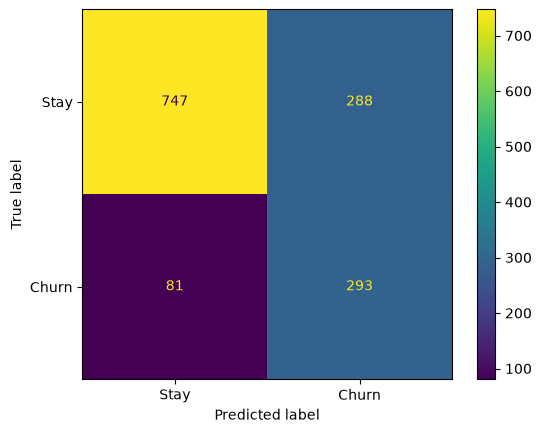

In [8]:
proba = baseline.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(classification_report(
    y_test,
    pred,
    target_names=["Stay", "Churn"]
))

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 3))
print("PR-AUC: ", round(average_precision_score(y_test, proba), 3))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred),
    display_labels=["Stay", "Churn"]
).plot()

plt.show()

In [9]:
rf = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                     class_weight="balanced", random_state=42, n_jobs=-1)),
])

lgbm = Pipeline([
    ("prep", preprocess),
    ("model", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15,
                             class_weight="balanced", random_state=42, verbose=-1)),
])

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall"}

results = {}
for name, model in [("Logistic", baseline), ("RandomForest", rf), ("LightGBM", lgbm)]:
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    results[name] = {k: scores[f"test_{k}"].mean().round(3) for k in scoring}

pd.DataFrame(results).T

,roc_auc,pr_auc,recall
Logistic,0.846,0.660,0.801
RandomForest,0.845,0.653,0.761
LightGBM,0.843,0.656,0.761


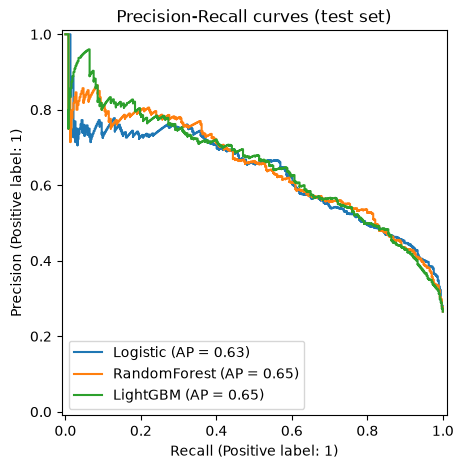

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in [("Logistic", baseline), ("RandomForest", rf), ("LightGBM", lgbm)]:
    model.fit(X_train, y_train)
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("Precision-Recall curves (test set)")
plt.show()

In [12]:
baseline.fit(X_train, y_train)
proba = baseline.predict_proba(X_test)[:, 1]

rows = []
for t in np.arange(0.2, 0.85, 0.05):
    pred = (proba >= t).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum()
    fp = ((pred == 1) & (y_test == 0)).sum()
    fn = ((pred == 0) & (y_test == 1)).sum()
    rows.append({"threshold": round(t, 2),
                 "flagged": tp + fp,
                 "precision": round(tp / (tp + fp), 3),
                 "recall": round(tp / (tp + fn), 3)})

pd.DataFrame(rows)

,threshold,flagged,precision,recall
0,0.20,927,0.388,0.963
1,0.25,863,0.407,0.939
2,0.30,808,0.429,0.928
3,0.35,756,0.447,0.904
4,0.40,694,0.467,0.866
5,0.45,650,0.483,0.840
6,0.50,581,0.504,0.783
7,0.55,535,0.525,0.751
8,0.60,489,0.540,0.706
9,0.65,439,0.567,0.666


threshold       0.725
contacted     332.000
profit       6260.000
Name: 25, dtype: float64


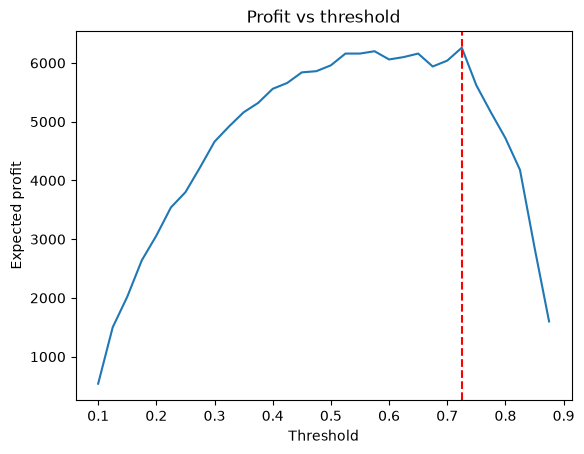

In [13]:
# Assumptions (state these in your README):
# - A retention offer costs 20 per customer contacted
# - Saving a churner is worth 200 (about 10 months of average revenue kept)
# - The offer succeeds 30% of the time
offer_cost = 20
value_saved = 200
success_rate = 0.30

profits = []
for t in np.arange(0.1, 0.9, 0.025):
    pred = (proba >= t).astype(int)
    tp = ((pred == 1) & (y_test == 1)).sum()
    contacted = pred.sum()
    profit = tp * success_rate * value_saved - contacted * offer_cost
    profits.append((round(t, 3), contacted, profit))

profit_df = pd.DataFrame(profits, columns=["threshold", "contacted", "profit"])
best = profit_df.loc[profit_df["profit"].idxmax()]
print(best)

plt.plot(profit_df["threshold"], profit_df["profit"])
plt.axvline(best["threshold"], color="red", linestyle="--")
plt.xlabel("Threshold")
plt.ylabel("Expected profit")
plt.title("Profit vs threshold")
plt.show()

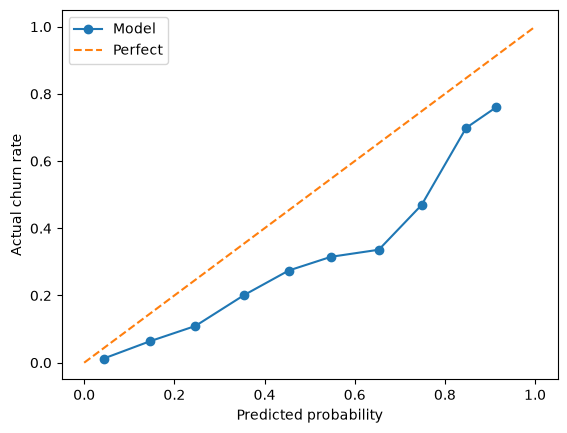

In [14]:
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10)
plt.plot(mean_pred, frac_pos, marker="o", label="Model")
plt.plot([0, 1], [0, 1], "--", label="Perfect")
plt.xlabel("Predicted probability")
plt.ylabel("Actual churn rate")
plt.legend()
plt.show()

ROC-AUC: 0.842
PR-AUC:  0.634


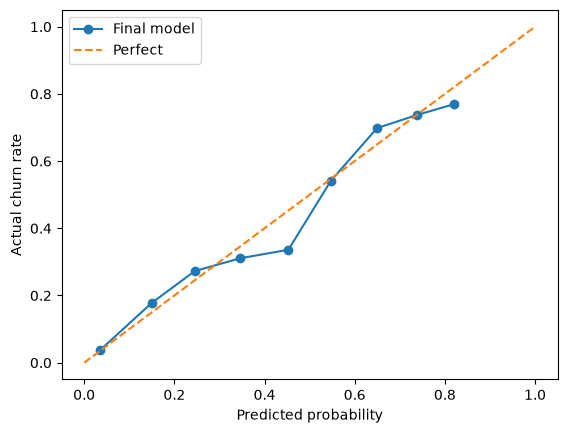

In [16]:
from sklearn.calibration import calibration_curve

final = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])

final.fit(X_train, y_train)

proba_f = final.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, proba_f), 3))
print("PR-AUC: ", round(average_precision_score(y_test, proba_f), 3))

frac_pos, mean_pred = calibration_curve(
    y_test,
    proba_f,
    n_bins=10
)

plt.plot(mean_pred, frac_pos, marker="o", label="Final model")
plt.plot([0, 1], [0, 1], "--", label="Perfect")

plt.xlabel("Predicted probability")
plt.ylabel("Actual churn rate")
plt.legend()
plt.show()

In [17]:
from sklearn.model_selection import cross_val_predict

def profit_per_customer(t, p, y, offer_cost=20, value_saved=200, success=0.30):
    pred = p >= t
    tp = (pred & (y == 1)).sum()
    return (tp * success * value_saved - pred.sum() * offer_cost) / len(y)

# Out-of-fold predictions on the training set (no test data involved)
oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

ts = np.arange(0.05, 0.8, 0.025)
train_profit = [profit_per_customer(t, oof, y_train.values) for t in ts]
best_t = ts[int(np.argmax(train_profit))]
print("Best threshold (chosen on train CV):", round(best_t, 3))

# Evaluate on test ONCE, and compare strategies
print("\nExpected profit per customer on the test set:")
print("Contact nobody:        0.00")
print("Contact everyone:     ", round(profit_per_customer(0.0, proba_f, y_test.values), 2))
print("Threshold 0.50:       ", round(profit_per_customer(0.5, proba_f, y_test.values), 2))
print(f"Chosen threshold {best_t:.2f}:", round(profit_per_customer(best_t, proba_f, y_test.values), 2))

Best threshold (chosen on train CV): 0.35

Expected profit per customer on the test set:
Contact nobody:        0.00
Contact everyone:      -4.07
Threshold 0.50:        4.39
Chosen threshold 0.35: 4.34


Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


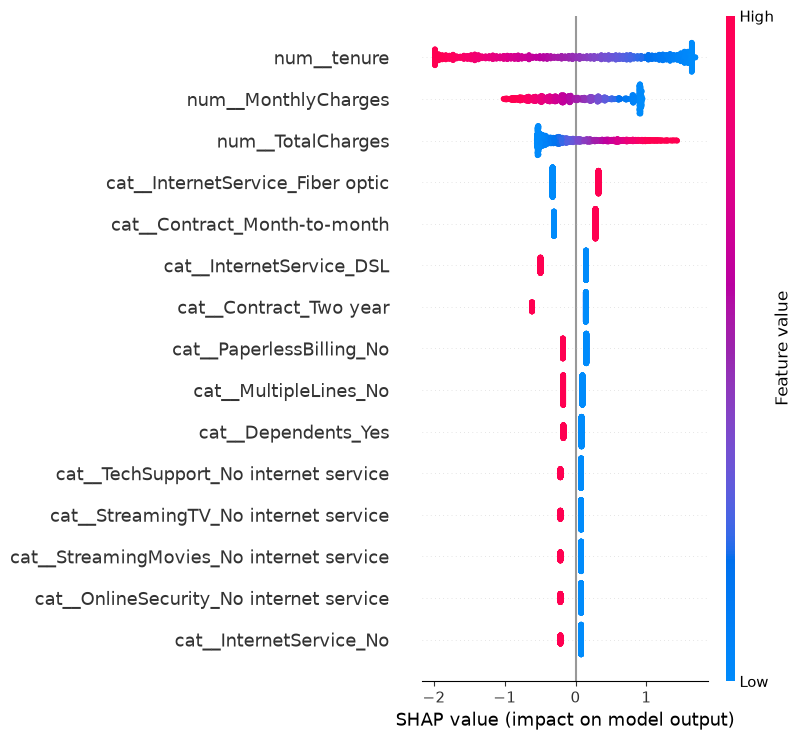

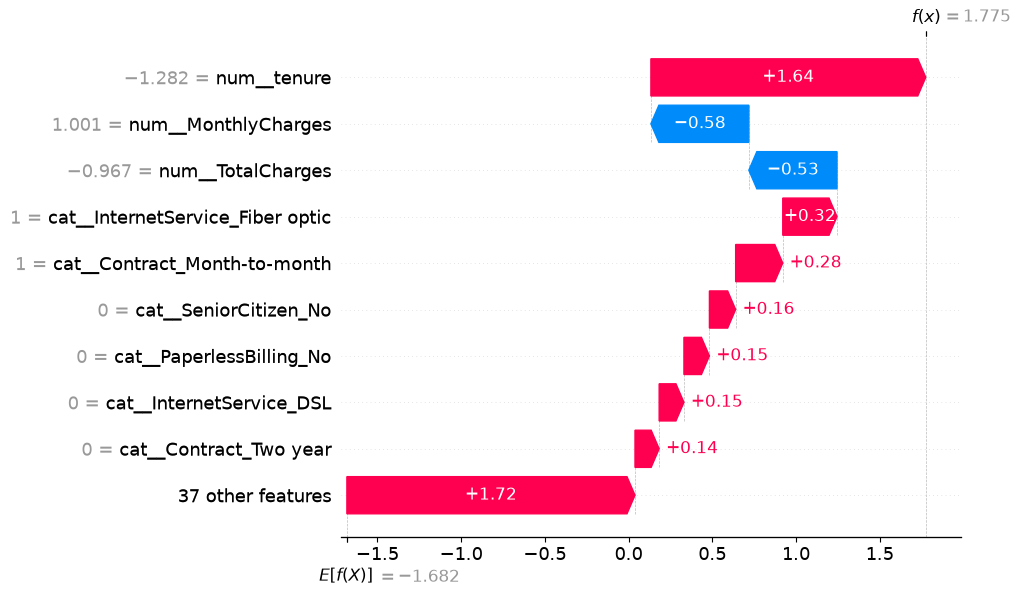

In [18]:
import shap

prep = final.named_steps["prep"]
clf = final.named_steps["model"]
names = prep.get_feature_names_out()

def dense(m):
    return m.toarray() if hasattr(m, "toarray") else m

Xtr_d = dense(prep.transform(X_train))
Xte_d = dense(prep.transform(X_test))

explainer = shap.LinearExplainer(clf, Xtr_d)
shap_values = explainer.shap_values(Xte_d)

# Global view: top churn drivers
shap.summary_plot(shap_values, Xte_d, feature_names=names, max_display=15)

# Individual view: one high-risk customer
i = int(np.argmax(proba_f))
exp = shap.Explanation(values=shap_values[i], base_values=explainer.expected_value,
                       data=Xte_d[i], feature_names=names)
shap.plots.waterfall(exp, max_display=10)

In [19]:
import joblib, json, os
os.makedirs("../app", exist_ok=True)

joblib.dump(final, "../app/model.joblib")
json.dump({"threshold": float(best_t)}, open("../app/config.json", "w"))
print("Saved.")

Saved.


In [20]:
group = []
for n in names:
    base = n.split("__", 1)[1]
    if n.startswith("num__"):
        group.append(base)
    else:
        group.append(next(c for c in cat_cols if base.startswith(c + "_")))

joblib.dump({"means": Xtr_d.mean(axis=0), "groups": group},
            "../app/explain.joblib")
print("Saved explain.joblib")

Saved explain.joblib


In [21]:
base = {
    "gender": "Male", "SeniorCitizen": "No", "Partner": "No", "Dependents": "No",
    "PhoneService": "Yes", "MultipleLines": "No",
    "PaperlessBilling": "Yes",
}

customer_A = {**base,
    "tenure": 1, "MonthlyCharges": 70.0,
    "Contract": "Month-to-month", "InternetService": "Fiber optic",
    "PaymentMethod": "Electronic check", "PaperlessBilling": "Yes",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No",
    "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No",
}

customer_B = {**base,
    "tenure": 60, "MonthlyCharges": 55.0,
    "Contract": "Two year", "InternetService": "DSL",
    "PaymentMethod": "Credit card (automatic)", "PaperlessBilling": "No",
    "OnlineSecurity": "No", "OnlineBackup": "No", "DeviceProtection": "No",
    "TechSupport": "No", "StreamingTV": "No", "StreamingMovies": "No",
}

for name, c in [("A", customer_A), ("B", customer_B)]:
    c["TotalCharges"] = c["tenure"] * c["MonthlyCharges"]
    row = pd.DataFrame([c])[X_train.columns]   # same column order as training
    print(f"Customer {name}: {final.predict_proba(row)[0, 1]:.1%}")

Customer A: 70.6%
Customer B: 1.1%


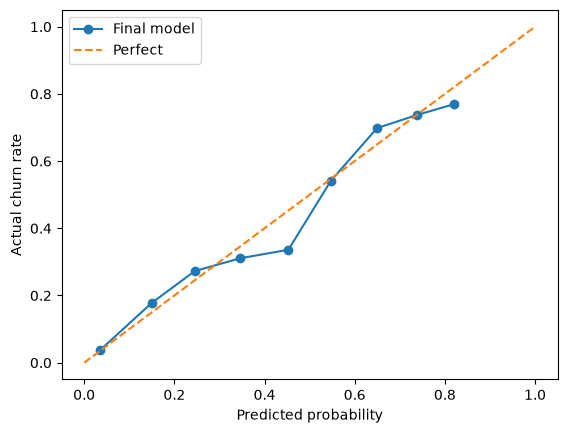

In [22]:
frac_pos, mean_pred = calibration_curve(y_test, proba_f, n_bins=10)
plt.plot(mean_pred, frac_pos, marker="o", label="Final model")
plt.plot([0, 1], [0, 1], "--", label="Perfect")
plt.xlabel("Predicted probability")
plt.ylabel("Actual churn rate")
plt.legend()
plt.show()